# Puentes y puntos de articulación

En un grafo no dirigido, un puente es una arista cuya eliminación aumenta el número de componentes conexas, y un punto de articulación es un nodo con esa misma propiedad. Tarjan los encuentra en un DFS calculando para cada nodo su tiempo de descubrimiento $t(u)$ y $bajo(u)$, el menor tiempo alcanzable desde su subárbol con una arista de retroceso. La arista $(u, v)$ del árbol es puente si $bajo(v) > t(u)$, y $u$ es de articulación si $bajo(v) \ge t(u)$ para algún hijo $v$ (o si es la raíz y tiene más de un hijo). Cuesta $O(V + E)$.

## 1. Algoritmo de Tarjan

Implementar el cálculo de puentes y puntos de articulación y aplicarlo a una red de carreteras entre pueblos.

In [1]:
import random
import sys

import matplotlib.pyplot as plt

sys.setrecursionlimit(10_000)

def puentes_y_articulaciones(grafo):
    t, bajo, puentes, articulaciones = {}, {}, set(), set()

    def dfs(u, padre):
        t[u] = bajo[u] = len(t)
        hijos = 0
        for v in grafo[u]:
            if v == padre:
                continue
            if v in t:
                bajo[u] = min(bajo[u], t[v])
            else:
                hijos += 1
                dfs(v, u)
                bajo[u] = min(bajo[u], bajo[v])
                if bajo[v] > t[u]:
                    puentes.add(frozenset((u, v)))
                if padre is not None and bajo[v] >= t[u]:
                    articulaciones.add(u)
        if padre is None and hijos > 1:
            articulaciones.add(u)

    for u in grafo:
        if u not in t:
            dfs(u, None)
    return puentes, articulaciones

def no_dirigido(aristas, nodos=()):
    g = {u: set() for u in nodos}
    for u, v in aristas:
        g.setdefault(u, set()).add(v)
        g.setdefault(v, set()).add(u)
    return g

carreteras = [("Agaete", "Gáldar"), ("Gáldar", "Guía"), ("Guía", "Moya"), ("Moya", "Firgas"), ("Firgas", "Arucas"),
              ("Arucas", "Moya"), ("Arucas", "Las Palmas"), ("Las Palmas", "Telde"), ("Telde", "Valsequillo"),
              ("Valsequillo", "Las Palmas"), ("Telde", "Ingenio")]
g = no_dirigido(carreteras)
puentes, articulaciones = puentes_y_articulaciones(g)
print("puentes:", sorted(tuple(sorted(p)) for p in puentes))
print("articulación:", sorted(articulaciones))

puentes: [('Agaete', 'Gáldar'), ('Arucas', 'Las Palmas'), ('Guía', 'Gáldar'), ('Guía', 'Moya'), ('Ingenio', 'Telde')]
articulación: ['Arucas', 'Guía', 'Gáldar', 'Las Palmas', 'Moya', 'Telde']


## 2. Contra fuerza bruta

Comprobarlo en grafos aleatorios quitando cada arista y cada nodo y contando componentes.

In [2]:
def componentes(grafo, sin_nodo=None, sin_arista=None):
    vistos, total = set(), 0
    for inicio in grafo:
        if inicio in vistos or inicio == sin_nodo:
            continue
        total += 1
        pila = [inicio]
        vistos.add(inicio)
        while pila:
            u = pila.pop()
            for v in grafo[u]:
                if v == sin_nodo or v in vistos or frozenset((u, v)) == sin_arista:
                    continue
                vistos.add(v)
                pila.append(v)
    return total

random.seed(1)
for _ in range(400):
    n = random.randint(1, 9)
    aristas = [(u, v) for u in range(n) for v in range(u + 1, n) if random.random() < 0.3]
    ga = no_dirigido(aristas, range(n))
    base = componentes(ga)
    pu, art = puentes_y_articulaciones(ga)
    assert pu == {frozenset(a) for a in aristas if componentes(ga, sin_arista=frozenset(a)) > base}
    assert art == {u for u in ga if componentes(ga, sin_nodo=u) > base - (len(ga[u]) == 0)}
print("ok")

ok


## 3. Dibujar la red

Dibujar la red de carreteras marcando los puentes en rojo y los puntos de articulación más grandes.

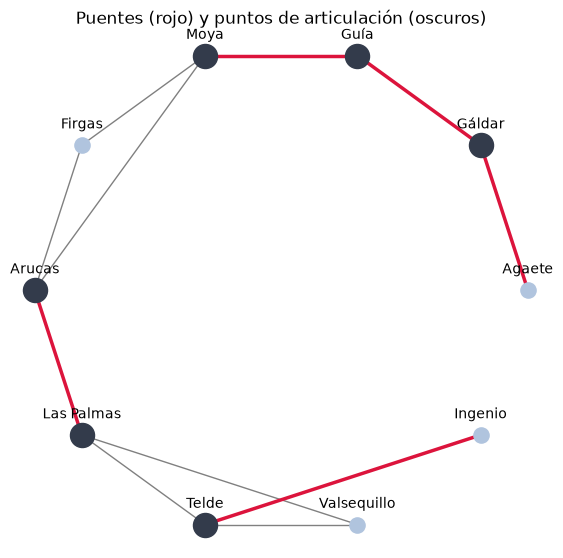

In [3]:
import math

nodos = list(g)
pos = {u: (math.cos(2 * math.pi * i / len(nodos)), math.sin(2 * math.pi * i / len(nodos))) for i, u in enumerate(nodos)}
fig, eje = plt.subplots(figsize=(7, 7))
for u, v in carreteras:
    rojo = frozenset((u, v)) in puentes
    eje.plot(*zip(pos[u], pos[v]), color="crimson" if rojo else "gray", linewidth=2.5 if rojo else 1, zorder=1)
for u, (x, y) in pos.items():
    es_art = u in articulaciones
    eje.scatter(x, y, s=300 if es_art else 120, color="#333b4b" if es_art else "lightsteelblue", zorder=2)
    eje.annotate(u, (x, y), textcoords="offset points", xytext=(0, 12), ha="center")
eje.set_title("Puentes (rojo) y puntos de articulación (oscuros)")
eje.set_aspect("equal")
eje.axis("off")
plt.show()

## 4. Componentes biconexas por aristas

Quitar todos los puentes y obtener las componentes que quedan: dentro de cada una, cualquier par de pueblos sigue conectado aunque se corte una carretera.

In [4]:
sin_puentes = {u: {v for v in g[u] if frozenset((u, v)) not in puentes} for u in g}
vistos, grupos = set(), []
for u in sin_puentes:
    if u in vistos:
        continue
    grupo, pila = [], [u]
    vistos.add(u)
    while pila:
        x = pila.pop()
        grupo.append(x)
        for y in sin_puentes[x] - vistos:
            vistos.add(y)
            pila.append(y)
    grupos.append(sorted(grupo))
for grupo in grupos:
    print(grupo)
assert len(grupos) == len(puentes) + 1  # el grafo es conexo: cada puente separa un bloque

['Agaete']
['Gáldar']
['Guía']
['Arucas', 'Firgas', 'Moya']
['Las Palmas', 'Telde', 'Valsequillo']
['Ingenio']
